### **Student Information**
GitHub ID: weifu-yee

Kaggle name: 115062806 weifu-yee

Kaggle score: 0.6107

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*姓名、學號及 API key 只放在 git-ignored 的 <code>config/.env</code>，不要填入公開 notebook。*


---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

# **Project Report**

## 1. Model Development

### 1.1 Preprocessing Steps

這次使用 Kaggle 提供的四個檔案，以 <code>post_id</code> 合併貼文、train/test 身分與訓練標籤，共 3,360 筆訓練資料、1,440 筆測試資料。六類訓練數量為 anger 674、disgust 454、fear 288、joy 875、sadness 628、surprise 441，並不平衡，因此主要比較 macro F1。

文字只做 HTML entity 還原與空白正規化，保留否定詞、emoji、標點及原本大小寫，避免先移除情緒線索。TF-IDF 另使用向量器預設的小寫轉換。資料檢查包含 ID 唯一性、缺值、空文字、標籤集合及 train/test 對應關係，沒有使用測試標籤。

訓練資料依清理後再 <code>casefold()</code> 的文字分組，有 50 筆超出首次出現的重複列，其中 16 組文字對應不同標籤，因此保留原標註，沒有直接去重。train/test 另有 59 組相同的標準化文字。驗證使用 <code>StratifiedGroupKFold</code>，讓相同文字留在同一個 fold；TF-IDF 的詞彙表與 IDF 都只在該 fold 的訓練部分擬合。

### 1.2 Feature Engineering Steps

稀疏特徵結合 word unigram/bigram TF-IDF（<code>min_df=1</code>）與 <code>char_wb</code> 3–5 gram TF-IDF（<code>min_df=2</code>，最多 100,000 個字元特徵），兩者都使用 <code>sublinear_tf=True</code>。word 特徵保留詞與短語，字元特徵補充拼字變化與局部字串。

也比較了 [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) 的 384 維與 [MPNet](https://huggingface.co/sentence-transformers/all-mpnet-base-v2) 的 768 維固定句向量。最後 SVM 使用 word TF-IDF、char TF-IDF 與乘上 0.5 的 L2 正規化固定 MPNet 向量串接。另一條路徑則直接微調 MPNet encoder，讓表示學習使用本次六類標籤。使用的預訓練權重版本固定於程式，沒有載入外部情緒標籤或已微調的情緒分類器。

### 1.3 Explanation of Your Model

先用 TF-IDF＋LinearSVC 建立 baseline。word＋char、<code>C=1</code>、<code>class_weight="balanced"</code> 的第一組三折平均 macro F1 是 0.4976；加入固定句向量、調整正則化後，再比較微調 encoder 與融合。

最終由兩個模型組成：

- **SVM：** 使用上述稀疏＋固定 MPNet 特徵，<code>LinearSVC(C=0.03, class_weight="balanced", random_state=42)</code>。
- **微調 MPNet：** attention-mask mean pooling 後接 dropout 0.1 與六類線性 head。使用 AdamW，encoder/head learning rate 分別為 2e-5／5e-4，weight decay 0.01、batch size 32、最大長度 96、label smoothing 0.03。loss 的 class weight 依各 fold 訓練類別頻率的平方根反比計算。第一組驗證比較 1–6 epoch，平均 F1 在第 5 epoch 最好；第二組驗證與全部資料重訓使用 5 epoch。

融合前將神經模型 softmax 分數的溫度設為 1.5，SVM 分數經 softmax 後的溫度設為 0.5，再各占一半：

<code>score = 0.5 * softmax(log(p_MPNet) / 1.5) + 0.5 * softmax(log(p_SVM) / 0.5)</code>

實作先將分數裁切至不小於 1e-12，避免 <code>log(0)</code>。這讓神經模型的分數較平緩、SVM 的分數較集中；最後取最高分的類別。這些分數用於融合，並不宣稱是校準過的機率。類別 prior 調整也有比較，但驗證沒有改善，最終 <code>prior_power=0</code>。

後續模型都用 seed 42、2026 各做三折分組驗證，下表是 macro F1：

| 設定 | seed 42 平均 | seed 2026 平均 | 六個 fold 平均 |
| --- | ---: | ---: | ---: |
| TF-IDF＋固定 MPNet＋SVM | 0.5645 | 0.5623 | 0.5634 |
| 微調 MPNet | 0.5839 | 0.5886 | 0.5863 |
| 微調 MPNet＋SVM，等權融合 | 0.5866 | 0.5922 | 0.5894 |
| 微調 DeBERTa | 0.5421 | 0.5170 | 0.5295 |
| 微調 DeBERTa＋微調 MPNet | 0.5906 | 0.5813 | 0.5860 |
| 最終：MPNet＋SVM，調整融合尺度 | 0.5889 | 0.5968 | 0.5929 |

最終融合尺度相較等權原版提高約 0.0034，兩組切分都有增加。這次的 DeBERTa 設定沒有勝過 MPNet 路徑，因此沒有放進最後提交。這些驗證標籤同時用來挑 epoch、參數及融合設定，六個 fold 也來自同一批訓練資料，不是完全獨立的測試。後續實驗亦受 Kaggle 回報啟發，所以不能把多輪選擇後的結果當成不偏的泛化估計。

選定設定後，以全部 3,360 筆有標籤資料重訓。第四版 <code>submission_v4.csv</code> 有 1,440 筆預測，依範本的 ID 順序輸出；範本使用 <code>post_id</code>，但實際評分器要求 <code>id</code>，因此提交欄名改為 <code>id,label</code>。本人回報此檔的 Kaggle 成績為 **0.6107**；這不是本地驗證的 0.5929。榜別及最終私榜排名仍須以 Kaggle 頁面與截圖核對。

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

以下整理本次使用的 prompts、採用或拒絕的建議，以及對應的實驗依據。

| AI 建議 | 本次決定與依據 |
| --- | --- |
| 先做 TF-IDF＋SVM，再加句向量 | 採用，先取得可提交的 baseline，再比較表示與正則化。 |
| 依重複文字分組驗證 | 採用，避免相同文字跨訓練與驗證，使比較更合理。 |
| 微調 MPNet 並與 SVM 融合 | 採用，六個 fold 平均由固定 MPNet 混合特徵的 0.5634 提高至 0.5894。 |
| 換用 DeBERTa，並嘗試融合 | 已實跑，但沒有勝過前版，未採用。 |
| 調整融合尺度與類別 prior | 採用溫度 1.5／0.5 的設定，驗證為 0.5929；未採用 prior 調整。 |
| 將範本欄名直接當作提交格式 | 初次提交被拒後修正為 <code>id,label</code>，保留 ID、順序及預測。 |

<details>
<summary>本次 Kaggle 相關 AI 對話請求與回報</summary>

以下保留實際請求；連結改以檔名或分數表示，沒有把事後的模型選擇改寫成事前指定。

1. 「研究一下這個 lab 要怎麼完成」
2. 「目前請先幫我規劃到完成 kaggle。有需要先 fork github repo 嗎?」
3. 「我 fork 好了:」並提供 <code>weifu-yee/DM2026-Lab2-Exercise</code> 連結。
4. 「好了」：回報四個資料檔已放入資料夾。
5. 「我 kaggle 的 team 應該要改叫什麼?」
6. 「lab2_submission_guilde.md 有沒有提到?」
7. 「Error: "ID column id not found in submission"」
8. 「score is」並回報 <code>0.5394</code>。
9. 「可以更高嗎?」
10. 「0.5826。這樣可以拿到幾分　並在幫我試是能不能更高」；另確認這是 Public Score、私榜尚未公布。
11. 「有 100 隊伍」
12. 「幫我在試試能不能更高分，別管排名了」
13. 「我 Kaggle 已經達到 0.6107 分。現在開始完成此作業其他部分」
14. 「喔這個要我跟 ipynb 互動的部分請不要幫我做，我會自己做」；另確認 <code>0.6107</code> 對應 <code>submission_v4.csv</code>。
15. 「你先幫我好好規劃一份 guidance for me，用中文簡潔有力告訴我要幹嘛」
16. 「像是 kaggle 的其他部分 (報告之類的)  你f現在就可以幫我完成」

</details>


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
from pathlib import Path
import html
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
LABELS = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
DATA_DIR = Path('data/kaggle')
OUTPUT_DIR = Path('outputs/kaggle')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = ['final_posts.json', 'emotion.csv', 'data_identification.csv', 'sampleSubmission.csv']
missing = [name for name in required if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Place the Kaggle data in {DATA_DIR.resolve()}: {missing}')

posts = pd.DataFrame(json.loads((DATA_DIR / 'final_posts.json').read_text(encoding='utf-8')))
membership = pd.read_csv(DATA_DIR / 'data_identification.csv', dtype=str)
labels = pd.read_csv(DATA_DIR / 'emotion.csv', dtype=str)
sample = pd.read_csv(DATA_DIR / 'sampleSubmission.csv', dtype=str)
assert posts.columns.tolist() == ['post_id', 'text']
assert membership.columns.tolist() == ['post_id', 'set']
assert labels.columns.tolist() == ['post_id', 'label']
assert sample.columns.tolist() == ['post_id', 'label'], 'Check the actual submission template.'
for table in [posts, membership, labels, sample]:
    assert table['post_id'].notna().all() and table['post_id'].is_unique
assert membership['set'].isin(['train', 'test']).all()
assert set(posts['post_id']) == set(membership['post_id'])
assert set(labels['post_id']) == set(membership.loc[membership['set'].eq('train'), 'post_id'])
assert set(labels['label']) == set(LABELS)

data = membership.merge(posts, on='post_id', validate='one_to_one').merge(
    labels, on='post_id', how='left', validate='one_to_one'
)
assert data['text'].map(lambda value: isinstance(value, str)).all()

def clean_text(text):
    # Keep negation, emoji, punctuation, and capitalization for later embeddings.
    return re.sub(r'\s+', ' ', html.unescape(text)).strip()

data['clean_text'] = data['text'].map(clean_text)
data['group'] = data['clean_text'].str.casefold()
assert data['clean_text'].ne('').all()
train = data.loc[data['set'].eq('train')].reset_index(drop=True)
test = data.loc[data['set'].eq('test')].reset_index(drop=True)
assert train['label'].notna().all() and test['label'].isna().all()
assert set(sample['post_id']) == set(test['post_id'])

display(train['label'].value_counts().reindex(LABELS).rename('train_count').to_frame())
audit = pd.Series({
    'train_rows': len(train), 'test_rows': len(test),
    'duplicate_train_texts': int(train['group'].duplicated().sum()),
    'duplicate_test_texts': int(test['group'].duplicated().sum()),
    'shared_train_test_texts': len(set(train['group']) & set(test['group'])),
    'train_texts_with_multiple_labels': int((train.groupby('group')['label'].nunique() > 1).sum()),
}, name='count')
display(audit.to_frame())

X = train['clean_text']
y = train['label'].to_numpy()
# Keep all annotations; prevent the same normalized text crossing validation folds.
splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(splitter.split(X, y, groups=train['group']))
for fit_idx, valid_idx in folds:
    assert set(train.iloc[fit_idx]['group']).isdisjoint(train.iloc[valid_idx]['group'])
display(pd.DataFrame([
    {'fold': i + 1, 'train': len(a), 'validation': len(b)}
    for i, (a, b) in enumerate(folds)
]))


,train_count
label,
anger,674
disgust,454
fear,288
joy,875
sadness,628
surprise,441


,count
train_rows,3360
test_rows,1440
duplicate_train_texts,50
duplicate_test_texts,8
shared_train_test_texts,59
train_texts_with_multiple_labels,16


,fold,train,validation
0,1,2240,1120
1,2,2240,1120
2,3,2240,1120


## 2. Feature Engineering Steps

In [2]:
def make_features(kind):
    word = TfidfVectorizer(
        ngram_range=(1, 1) if kind == 'word_unigram' else (1, 2),
        min_df=1, sublinear_tf=True, dtype=np.float32,
    )
    if kind != 'word_char':
        return word
    char = TfidfVectorizer(
        analyzer='char_wb', ngram_range=(3, 5), min_df=2,
        max_features=100_000, sublinear_tf=True, dtype=np.float32,
    )
    return FeatureUnion([('word', word), ('char', char)])

def make_text_model(kind, C=1.0, balanced=False, classifier='svm'):
    model = ComplementNB(alpha=0.5) if classifier == 'nb' else LinearSVC(
        C=C, class_weight='balanced' if balanced else None,
        random_state=SEED, max_iter=10_000,
    )
    # Each fold fits its own vocabulary and IDF; validation/test text is only transformed.
    return Pipeline([('features', make_features(kind)), ('classifier', model)])

candidates = {
    'word_unigram_svm_C1': make_text_model('word_unigram'),
    'word_bigram_svm_C1': make_text_model('word_bigram'),
    'word_bigram_svm_C4': make_text_model('word_bigram', C=4),
    'word_bigram_svm_C1_balanced': make_text_model('word_bigram', balanced=True),
    'word_char_svm_C1': make_text_model('word_char'),
    'word_char_svm_C4': make_text_model('word_char', C=4),
    'word_char_svm_C1_balanced': make_text_model('word_char', balanced=True),
    'word_bigram_complement_nb': make_text_model('word_bigram', classifier='nb'),
}


## 3. Model Implementation Steps

word_unigram_svm_C1: macro F1 0.4705 +/- 0.0076


word_bigram_svm_C1: macro F1 0.4718 +/- 0.0142


word_bigram_svm_C4: macro F1 0.4696 +/- 0.0102


word_bigram_svm_C1_balanced: macro F1 0.4744 +/- 0.0100


word_char_svm_C1: macro F1 0.4970 +/- 0.0047


word_char_svm_C4: macro F1 0.4865 +/- 0.0013


word_char_svm_C1_balanced: macro F1 0.4976 +/- 0.0035


word_bigram_complement_nb: macro F1 0.4608 +/- 0.0048


,model,macro_f1_mean,macro_f1_std,oof_macro_f1,oof_accuracy,seconds,fold_1,fold_2,fold_3
0,word_char_svm_C1_balanced,0.4976,0.0035,0.4978,0.5179,2.3939,0.4930,0.4983,0.5014
1,word_char_svm_C1,0.4970,0.0047,0.4972,0.5199,2.9004,0.4904,0.4996,0.5010
2,word_char_svm_C4,0.4865,0.0013,0.4868,0.5074,4.4585,0.4868,0.4879,0.4849
3,word_bigram_svm_C1_balanced,0.4744,0.0100,0.4748,0.4955,0.5895,0.4787,0.4839,0.4606
4,word_bigram_svm_C1,0.4718,0.0142,0.4723,0.4991,0.6575,0.4738,0.4881,0.4534
5,word_unigram_svm_C1,0.4705,0.0076,0.4710,0.4923,0.2439,0.4739,0.4599,0.4777
6,word_bigram_svm_C4,0.4696,0.0102,0.4702,0.4935,1.0071,0.4776,0.4761,0.4552
7,word_bigram_complement_nb,0.4608,0.0048,0.4612,0.4917,0.3709,0.4550,0.4608,0.4667


,precision,recall,f1-score,support
anger,0.4804,0.5089,0.4942,674.0000
disgust,0.3714,0.3150,0.3409,454.0000
fear,0.5855,0.4757,0.5249,288.0000
joy,0.5936,0.6594,0.6248,875.0000
sadness,0.5148,0.5541,0.5337,628.0000
surprise,0.5066,0.4354,0.4683,441.0000
accuracy,0.5179,0.5179,0.5179,0.5179
macro avg,0.5087,0.4914,0.4978,3360.0000
weighted avg,0.5140,0.5179,0.5141,3360.0000


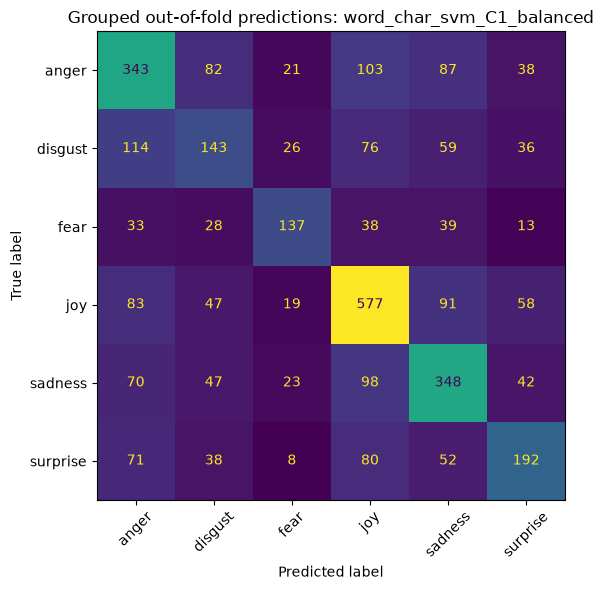

Selected: word_char_svm_C1_balanced
Saved 1440 predictions to outputs\kaggle\submission_tfidf.csv
These are model-selection validation scores, not Kaggle public/private scores.


,predicted_count
label,
anger,339
disgust,155
fear,107
joy,414
sadness,269
surprise,156


In [3]:
records = []
oof_predictions = {}
for name, candidate in candidates.items():
    start = time.perf_counter()
    oof = np.empty(len(y), dtype=object)
    scores = []
    for fit_idx, valid_idx in folds:
        estimator = clone(candidate)
        estimator.fit(X.iloc[fit_idx], y[fit_idx])
        predictions = estimator.predict(X.iloc[valid_idx])
        oof[valid_idx] = predictions
        scores.append(f1_score(y[valid_idx], predictions, labels=LABELS, average='macro', zero_division=0))
    oof_predictions[name] = oof
    row = {'model': name, 'macro_f1_mean': float(np.mean(scores)),
           'macro_f1_std': float(np.std(scores)),
           'oof_macro_f1': f1_score(y, oof, labels=LABELS, average='macro', zero_division=0),
           'oof_accuracy': accuracy_score(y, oof),
           'seconds': time.perf_counter() - start}
    row.update({f'fold_{i+1}': score for i, score in enumerate(scores)})
    records.append(row)
    print(f'{name}: macro F1 {row["macro_f1_mean"]:.4f} +/- {row["macro_f1_std"]:.4f}', flush=True)

results = pd.DataFrame(records).sort_values(
    ['macro_f1_mean', 'macro_f1_std'], ascending=[False, True]
).reset_index(drop=True)
results.to_csv(OUTPUT_DIR / 'tfidf_cv_results.csv', index=False)
display(results.round(4))
best_name = results.loc[0, 'model']
best_oof = oof_predictions[best_name]
display(pd.DataFrame(classification_report(y, best_oof, labels=LABELS, output_dict=True, zero_division=0)).T.round(4))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, best_oof, labels=LABELS, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f'Grouped out-of-fold predictions: {best_name}')
fig.tight_layout()
plt.show()

final_model = clone(candidates[best_name]).fit(X, y)
ordered_test = test.set_index('post_id').loc[sample['post_id'], 'clean_text']
# Kaggle requires id, although the downloaded template calls it post_id.
submission = sample.rename(columns={'post_id': 'id'}).copy()
submission['label'] = final_model.predict(ordered_test)
assert submission.columns.tolist() == ['id', 'label']
assert submission['id'].tolist() == sample['post_id'].tolist()
assert submission['id'].is_unique and len(submission) == len(test)
assert not submission.isna().any().any() and submission['label'].isin(LABELS).all()
submission_path = OUTPUT_DIR / 'submission_tfidf.csv'
submission.to_csv(submission_path, index=False)
saved = pd.read_csv(submission_path, dtype=str)
pd.testing.assert_frame_equal(saved, submission)
pd.DataFrame({'post_id': train['post_id'], 'label': y, 'oof_prediction': best_oof}).to_csv(
    OUTPUT_DIR / 'tfidf_oof_predictions.csv', index=False
)
(OUTPUT_DIR / 'tfidf_run.json').write_text(json.dumps({
    'seed': SEED, 'splitter': 'StratifiedGroupKFold', 'folds': len(folds),
    'selection_metric': 'mean validation macro F1', 'best_model': best_name,
    'train_rows': len(train), 'test_rows': len(test),
    'submission_columns': submission.columns.tolist(),
}, indent=2), encoding='utf-8')
print(f'Selected: {best_name}')
print(f'Saved {len(saved)} predictions to {submission_path}')
print('These are model-selection validation scores, not Kaggle public/private scores.')
display(submission.head())
display(submission['label'].value_counts().reindex(LABELS).rename('predicted_count').to_frame())


## 4. Pretrained Sentence Features

使用 [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) 的固定預訓練權重產生 384 維向量，不用競賽標籤微調 encoder。分類器沿用前面相同的分組驗證 folds。模型版本與文字順序列入 cache key；換資料或權重會重新編碼。

In [3]:
import hashlib
import os
import torch
from huggingface_hub import snapshot_download
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from scipy import sparse

os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
torch.set_num_threads(4)
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
MODEL_REVISION = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
texts = train['clean_text'].tolist() + test['clean_text'].tolist()
cache_key = hashlib.sha256(json.dumps({
    'model': MODEL_ID, 'revision': MODEL_REVISION, 'texts': texts,
    'normalize': True, 'max_sequence_length': 256,
}, ensure_ascii=False).encode('utf-8')).hexdigest()[:16]
embedding_path = OUTPUT_DIR / f'minilm_{cache_key}.npz'
if embedding_path.is_file():
    with np.load(embedding_path) as cached:
        embeddings = cached['embeddings']
else:
    try:
        model_path = snapshot_download(MODEL_ID, revision=MODEL_REVISION, local_files_only=True, allow_patterns=['*.json', '*.txt', '*.safetensors'], ignore_patterns=['onnx/*', 'openvino/*'])
    except OSError:
        model_path = snapshot_download(
            MODEL_ID, revision=MODEL_REVISION, token=False,
            allow_patterns=['*.json', '*.txt', '*.safetensors'],
            ignore_patterns=['onnx/*', 'openvino/*'],
        )
    encoder = SentenceTransformer(model_path, device='cpu', local_files_only=True)
    encoder.max_seq_length = 256
    embeddings = encoder.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.savez_compressed(embedding_path, embeddings=embeddings)
assert embeddings.shape == (len(data), 384) and np.isfinite(embeddings).all()
E_train = embeddings[:len(train)]
E_test = embeddings[len(train):]
print('Embedding matrices:', E_train.shape, E_test.shape)


C:\_NTHU\03_Doctor\_021_修課-第一學期\01_資料探勘 Data Mining\Lab\DM2026-Lab2-Kaggle\DM2026-Lab2-Exercise\.venv-kaggle-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embedding matrices: (3360, 384) (1440, 384)


## 5. Model Comparison

比較固定句向量上的線性分類器、RBF SVM，以及 TF-IDF 與句向量的組合。所有候選使用同樣三折分組驗證，以平均 macro F1 選擇設定；這組分數用於模型選擇，並非獨立測試成績。

In [5]:
embedding_candidates = {
    'minilm_logreg_C1': LogisticRegression(C=1, max_iter=3000),
    'minilm_logreg_C4': LogisticRegression(C=4, max_iter=3000),
    'minilm_logreg_C1_balanced': LogisticRegression(C=1, class_weight='balanced', max_iter=3000),
    'minilm_linear_svm_C1': LinearSVC(C=1, random_state=SEED, max_iter=10000),
    'minilm_rbf_svm_C1': SVC(C=1, kernel='rbf'),
    'minilm_rbf_svm_C4': SVC(C=4, kernel='rbf'),
    'minilm_rbf_svm_C16': SVC(C=16, kernel='rbf'),
    'minilm_rbf_svm_C4_balanced': SVC(C=4, kernel='rbf', class_weight='balanced'),
}

def add_result(name, predictions, scores, elapsed):
    oof_predictions[name] = predictions
    row = {'model': name, 'macro_f1_mean': float(np.mean(scores)),
           'macro_f1_std': float(np.std(scores)),
           'oof_macro_f1': f1_score(y, predictions, labels=LABELS, average='macro', zero_division=0),
           'oof_accuracy': accuracy_score(y, predictions), 'seconds': elapsed}
    row.update({f'fold_{i+1}': score for i, score in enumerate(scores)})
    records.append(row)
    print(f'{name}: macro F1 {row["macro_f1_mean"]:.4f} +/- {row["macro_f1_std"]:.4f}', flush=True)

for name, candidate in embedding_candidates.items():
    start = time.perf_counter()
    oof = np.empty(len(y), dtype=object)
    scores = []
    for fit_idx, valid_idx in folds:
        estimator = clone(candidate).fit(E_train[fit_idx], y[fit_idx])
        predictions = estimator.predict(E_train[valid_idx])
        oof[valid_idx] = predictions
        scores.append(f1_score(y[valid_idx], predictions, labels=LABELS, average='macro', zero_division=0))
    add_result(name, oof, scores, time.perf_counter() - start)

# Fit vocabulary/IDF only on each fold's training rows, including for the hybrid.
hybrid_weights = {'hybrid_svm_weight1': 1.0, 'hybrid_svm_weight2': 2.0}
hybrid_classifiers = {name: LinearSVC(C=1, class_weight='balanced', random_state=SEED, max_iter=10000)
                      for name in hybrid_weights}
hybrid_oof = {name: np.empty(len(y), dtype=object) for name in hybrid_weights}
hybrid_scores = {name: [] for name in hybrid_weights}
start = time.perf_counter()
for fit_idx, valid_idx in folds:
    features = make_features('word_char')
    T_fit = features.fit_transform(X.iloc[fit_idx])
    T_valid = features.transform(X.iloc[valid_idx])
    for name, weight in hybrid_weights.items():
        H_fit = sparse.hstack([T_fit, weight * sparse.csr_matrix(E_train[fit_idx])], format='csr')
        H_valid = sparse.hstack([T_valid, weight * sparse.csr_matrix(E_train[valid_idx])], format='csr')
        estimator = clone(hybrid_classifiers[name]).fit(H_fit, y[fit_idx])
        predictions = estimator.predict(H_valid)
        hybrid_oof[name][valid_idx] = predictions
        hybrid_scores[name].append(f1_score(y[valid_idx], predictions, labels=LABELS, average='macro', zero_division=0))
elapsed = time.perf_counter() - start
for name in hybrid_weights:
    add_result(name, hybrid_oof[name], hybrid_scores[name], elapsed)

all_results = pd.DataFrame(records).sort_values(
    ['macro_f1_mean', 'macro_f1_std'], ascending=[False, True]
).reset_index(drop=True)
all_results.to_csv(OUTPUT_DIR / 'cv_results.csv', index=False)
display(all_results.round(4))


minilm_logreg_C1: macro F1 0.5061 +/- 0.0089


minilm_logreg_C4: macro F1 0.4824 +/- 0.0096


minilm_logreg_C1_balanced: macro F1 0.4928 +/- 0.0113


minilm_linear_svm_C1: macro F1 0.4837 +/- 0.0055


minilm_rbf_svm_C1: macro F1 0.4960 +/- 0.0068


minilm_rbf_svm_C4: macro F1 0.5002 +/- 0.0144


minilm_rbf_svm_C16: macro F1 0.5011 +/- 0.0147


minilm_rbf_svm_C4_balanced: macro F1 0.5023 +/- 0.0139


hybrid_svm_weight1: macro F1 0.5219 +/- 0.0074


hybrid_svm_weight2: macro F1 0.5038 +/- 0.0090


,model,macro_f1_mean,macro_f1_std,oof_macro_f1,oof_accuracy,seconds,fold_1,fold_2,fold_3
0,hybrid_svm_weight1,0.5219,0.0074,0.5221,0.5443,10.4317,0.5147,0.5188,0.5321
1,minilm_logreg_C1,0.5061,0.0089,0.5059,0.5387,0.3056,0.4937,0.5098,0.5146
2,hybrid_svm_weight2,0.5038,0.0090,0.5039,0.5259,10.4317,0.4944,0.5010,0.5158
3,minilm_rbf_svm_C4_balanced,0.5023,0.0139,0.5019,0.5336,6.3522,0.4861,0.5199,0.5009
4,minilm_rbf_svm_C16,0.5011,0.0147,0.5007,0.5327,4.8219,0.4832,0.5191,0.5010
5,minilm_rbf_svm_C4,0.5002,0.0144,0.4998,0.5318,5.2991,0.4831,0.5184,0.4990
6,word_char_svm_C1_balanced,0.4976,0.0035,0.4978,0.5179,2.3939,0.4930,0.4983,0.5014
7,word_char_svm_C1,0.4970,0.0047,0.4972,0.5199,2.9004,0.4904,0.4996,0.5010
8,minilm_rbf_svm_C1,0.4960,0.0068,0.4962,0.5354,4.9261,0.4866,0.5021,0.4992
9,minilm_logreg_C1_balanced,0.4928,0.0113,0.4925,0.5113,0.3303,0.4779,0.5052,0.4954


## 6. Prediction and Submission

依驗證平均 macro F1 選出設定，以全部有標籤資料重訓。測試資料不參與模型選擇。

下載的範本將識別欄命名為 `post_id`，但 Kaggle 的實際評分器要求 `id`。輸出時只將欄名改成 `id,label`，保留範本的 ID、列順序及模型預測。公開與私榜分數需提交 Kaggle 後另行記錄。

,precision,recall,f1-score,support
anger,0.4972,0.5356,0.5157,674.0000
disgust,0.4167,0.3634,0.3882,454.0000
fear,0.6009,0.4861,0.5374,288.0000
joy,0.6479,0.7086,0.6769,875.0000
sadness,0.5365,0.5382,0.5374,628.0000
surprise,0.4904,0.4649,0.4773,441.0000
accuracy,0.5443,0.5443,0.5443,0.5443
macro avg,0.5316,0.5161,0.5221,3360.0000
weighted avg,0.5409,0.5443,0.5413,3360.0000


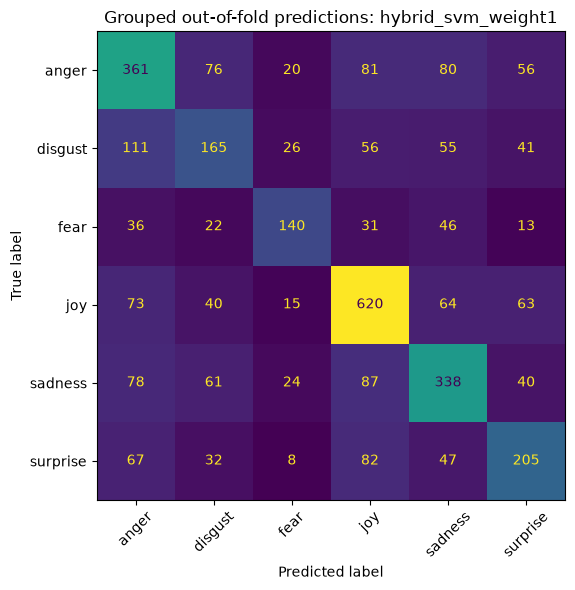

Selected: hybrid_svm_weight1
Saved 1440 predictions to outputs\kaggle\submission.csv
Kaggle public/private scores: not available until submission.


,predicted_count
label,
anger,322
disgust,170
fear,111
joy,406
sadness,258
surprise,173


In [6]:
selected_name = all_results.loc[0, 'model']
test_order = test.set_index('post_id').index.get_indexer(sample['post_id'])
assert (test_order >= 0).all()
if selected_name in candidates:
    selected_model = clone(candidates[selected_name]).fit(X, y)
    test_predictions = selected_model.predict(test.iloc[test_order]['clean_text'])
elif selected_name in embedding_candidates:
    selected_model = clone(embedding_candidates[selected_name]).fit(E_train, y)
    test_predictions = selected_model.predict(E_test[test_order])
else:
    final_features = make_features('word_char')
    final_T_train = final_features.fit_transform(X)
    final_T_test = final_features.transform(test.iloc[test_order]['clean_text'])
    weight = hybrid_weights[selected_name]
    final_H_train = sparse.hstack([final_T_train, weight * sparse.csr_matrix(E_train)], format='csr')
    final_H_test = sparse.hstack([final_T_test, weight * sparse.csr_matrix(E_test[test_order])], format='csr')
    selected_model = clone(hybrid_classifiers[selected_name]).fit(final_H_train, y)
    test_predictions = selected_model.predict(final_H_test)

# Kaggle requires id, although the downloaded template calls it post_id.
submission = sample.rename(columns={'post_id': 'id'}).copy()
submission['label'] = test_predictions
assert submission.columns.tolist() == ['id', 'label']
assert submission['id'].tolist() == sample['post_id'].tolist()
assert submission['id'].is_unique and len(submission) == len(test)
assert not submission.isna().any().any() and submission['label'].isin(LABELS).all()
submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path, dtype=str), submission)
selected_oof = oof_predictions[selected_name]
pd.DataFrame({'post_id': train['post_id'], 'label': y, 'oof_prediction': selected_oof}).to_csv(
    OUTPUT_DIR / 'oof_predictions.csv', index=False
)
display(pd.DataFrame(classification_report(y, selected_oof, labels=LABELS, output_dict=True, zero_division=0)).T.round(4))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, selected_oof, labels=LABELS, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f'Grouped out-of-fold predictions: {selected_name}')
fig.tight_layout()
plt.show()
import sklearn
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps({
    'seed': SEED, 'splitter': 'StratifiedGroupKFold', 'folds': len(folds),
    'selected_model': selected_name,
    'validation_macro_f1_mean': float(all_results.loc[0, 'macro_f1_mean']),
    'validation_macro_f1_std': float(all_results.loc[0, 'macro_f1_std']),
    'embedding_model': MODEL_ID, 'embedding_revision': MODEL_REVISION,
    'train_rows': len(train), 'test_rows': len(test),
    'submission_columns': submission.columns.tolist(),
    'numpy': np.__version__, 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
}, indent=2), encoding='utf-8')
print('Selected:', selected_name)
print(f'Saved {len(submission)} predictions to {submission_path}')
print('Kaggle public/private scores: not available until submission.')
display(submission.head())
display(submission['label'].value_counts().reindex(LABELS).rename('predicted_count').to_frame())


## 7. Submission Format Check

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

sample_ids = pd.read_csv('data/kaggle/sampleSubmission.csv', dtype=str)['post_id']
allowed_labels = {'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise'}
for name in ['submission.csv', 'submission_tfidf.csv']:
    path = Path('outputs/kaggle') / name
    checked = pd.read_csv(path, dtype=str)
    assert checked.columns.tolist() == ['id', 'label']
    assert checked['id'].tolist() == sample_ids.tolist()
    assert checked['id'].is_unique and not checked.isna().any().any()
    assert checked['label'].isin(allowed_labels).all()
    print(f'{name}: {len(checked)} rows; columns = {checked.columns.tolist()}')
display(pd.read_csv('outputs/kaggle/submission.csv', dtype=str).head())


submission.csv: 1440 rows; columns = ['id', 'label']
submission_tfidf.csv: 1440 rows; columns = ['id', 'label']


,id,label
0,xyzx9jp,anger
1,l3vzzxt,fear
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


## 8. Regularization and Feature Weights

沿用相同的分組驗證，進一步比較較強的正則化、句向量權重與 class weighting。所有設定只依訓練資料的驗證結果比較，不用 Kaggle 分數調整類別或單筆預測。

In [4]:
# Fixed folds and fold-specific vocabularies keep every candidate comparable.
from itertools import product
from scipy.special import softmax

fold_text_features = []
for fit_idx, valid_idx in folds:
    vectorizer = make_features('word_char')
    fold_text_features.append((vectorizer.fit_transform(X.iloc[fit_idx]),
                               vectorizer.transform(X.iloc[valid_idx])))

tuned_specs = {}
for C, weight, balanced in product([0.1, 0.5, 1.0], [0.5, 1.0], [False, True]):
    name = f'tuned_hybrid_C{C}_w{weight}_balanced{balanced}'
    tuned_specs[name] = {'representation': 'minilm_hybrid', 'classifier': 'svm',
                         'C': C, 'weight': weight, 'balanced': balanced}
for C in [0.03, 0.1, 0.3]:
    for classifier in ['svm', 'logreg']:
        tuned_specs[f'tuned_minilm_{classifier}_C{C}'] = {
            'representation': 'minilm', 'classifier': classifier,
            'C': C, 'weight': 1.0, 'balanced': False,
        }

def classifier_from_spec(spec):
    common = {'C': spec['C'], 'class_weight': 'balanced' if spec['balanced'] else None}
    if spec['classifier'] == 'logreg':
        return LogisticRegression(**common, max_iter=3000)
    return LinearSVC(**common, random_state=SEED, max_iter=10000)

def fold_matrices(spec, fold_number):
    fit_idx, valid_idx = folds[fold_number]
    encoder_name = 'mpnet' if spec['representation'].startswith('mpnet') else 'minilm'
    E = embedding_sets[encoder_name][0]
    if spec['representation'].endswith('hybrid'):
        T_fit, T_valid = fold_text_features[fold_number]
        return (sparse.hstack([T_fit, spec['weight'] * sparse.csr_matrix(E[fit_idx])], format='csr'),
                sparse.hstack([T_valid, spec['weight'] * sparse.csr_matrix(E[valid_idx])], format='csr'))
    return E[fit_idx], E[valid_idx]

embedding_sets = {'minilm': (E_train, E_test)}
tuned_records = []
tuned_decisions = {}

def evaluate_spec(name, spec):
    start = time.perf_counter()
    decisions = np.empty((len(y), len(LABELS)))
    fold_scores = []
    for fold_number, (fit_idx, valid_idx) in enumerate(folds):
        fit_matrix, valid_matrix = fold_matrices(spec, fold_number)
        estimator = classifier_from_spec(spec).fit(fit_matrix, y[fit_idx])
        assert estimator.classes_.tolist() == LABELS
        scores = estimator.decision_function(valid_matrix)
        decisions[valid_idx] = scores
        predictions = np.array(LABELS)[scores.argmax(axis=1)]
        fold_scores.append(f1_score(y[valid_idx], predictions, labels=LABELS,
                                    average='macro', zero_division=0))
    tuned_decisions[name] = decisions
    row = {'model': name, 'macro_f1_mean': float(np.mean(fold_scores)),
           'macro_f1_std': float(np.std(fold_scores)),
           'oof_macro_f1': f1_score(y, np.array(LABELS)[decisions.argmax(axis=1)],
                                    labels=LABELS, average='macro', zero_division=0),
           'seconds': time.perf_counter() - start}
    row.update({f'fold_{i+1}': value for i, value in enumerate(fold_scores)})
    tuned_records.append(row)
    print(f'{name}: {row["macro_f1_mean"]:.4f} +/- {row["macro_f1_std"]:.4f}', flush=True)

for name, spec in tuned_specs.items():
    evaluate_spec(name, spec)
tuning_results = pd.DataFrame(tuned_records).sort_values('macro_f1_mean', ascending=False)
tuning_results.to_csv(OUTPUT_DIR / 'tuning_minilm.csv', index=False)
np.savez_compressed(OUTPUT_DIR / 'tuning_minilm_decisions.npz', **tuned_decisions)
(OUTPUT_DIR / 'tuning_minilm_specs.json').write_text(json.dumps(tuned_specs, indent=2), encoding='utf-8')
display(tuning_results.round(4))


tuned_hybrid_C0.1_w0.5_balancedFalse: 0.5365 +/- 0.0088


tuned_hybrid_C0.1_w0.5_balancedTrue: 0.5582 +/- 0.0091


tuned_hybrid_C0.1_w1.0_balancedFalse: 0.5407 +/- 0.0143


tuned_hybrid_C0.1_w1.0_balancedTrue: 0.5493 +/- 0.0099


tuned_hybrid_C0.5_w0.5_balancedFalse: 0.5339 +/- 0.0063


tuned_hybrid_C0.5_w0.5_balancedTrue: 0.5360 +/- 0.0048


... (9 outputs left out)

tuned_minilm_logreg_C0.1: 0.3922 +/- 0.0048


tuned_minilm_svm_C0.3: 0.4947 +/- 0.0040


tuned_minilm_logreg_C0.3: 0.4841 +/- 0.0092


,model,macro_f1_mean,macro_f1_std,oof_macro_f1,seconds,fold_1,fold_2,fold_3
1,tuned_hybrid_C0.1_w0.5_balancedTrue,0.5582,0.0091,0.5585,1.1527,0.5468,0.5691,0.5587
3,tuned_hybrid_C0.1_w1.0_balancedTrue,0.5493,0.0099,0.5494,1.1974,0.5373,0.5616,0.5489
2,tuned_hybrid_C0.1_w1.0_balancedFalse,0.5407,0.0143,0.5408,1.1248,0.5233,0.5404,0.5584
0,tuned_hybrid_C0.1_w0.5_balancedFalse,0.5365,0.0088,0.5366,1.1702,0.5293,0.5313,0.5489
5,tuned_hybrid_C0.5_w0.5_balancedTrue,0.5360,0.0048,0.5364,1.7852,0.5343,0.5311,0.5425
4,tuned_hybrid_C0.5_w0.5_balancedFalse,0.5339,0.0063,0.5340,1.7200,0.5324,0.5271,0.5423
7,tuned_hybrid_C0.5_w1.0_balancedTrue,0.5321,0.0073,0.5324,3.2295,0.5222,0.5343,0.5398
6,tuned_hybrid_C0.5_w1.0_balancedFalse,0.5268,0.0081,0.5271,3.1597,0.5217,0.5206,0.5383
9,tuned_hybrid_C1.0_w0.5_balancedTrue,0.5263,0.0096,0.5267,4.9802,0.5215,0.5178,0.5397
8,tuned_hybrid_C1.0_w0.5_balancedFalse,0.5244,0.0059,0.5247,4.7225,0.5216,0.5189,0.5325


## 9. MPNet Features

比較另一個固定的通用預訓練模型 [all-mpnet-base-v2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2)。權重版本固定，encoder 不用競賽標籤訓練。

In [5]:
MPNET_ID = 'sentence-transformers/all-mpnet-base-v2'
MPNET_REVISION = 'e8c3b32edf5434bc2275fc9bab85f82640a19130'
mpnet_key = hashlib.sha256(json.dumps({
    'model': MPNET_ID, 'revision': MPNET_REVISION, 'texts': texts,
    'normalize': True, 'max_sequence_length': 384,
}, ensure_ascii=False).encode('utf-8')).hexdigest()[:16]
mpnet_path = OUTPUT_DIR / f'mpnet_{mpnet_key}.npz'
if mpnet_path.is_file():
    with np.load(mpnet_path) as cached:
        mpnet_embeddings = cached['embeddings']
else:
    try:
        snapshot = snapshot_download(MPNET_ID, revision=MPNET_REVISION, local_files_only=True, allow_patterns=['*.json', '*.txt', '*.safetensors'], ignore_patterns=['onnx/*', 'openvino/*'])
    except OSError:
        snapshot = snapshot_download(MPNET_ID, revision=MPNET_REVISION, token=False,
            allow_patterns=['*.json', '*.txt', '*.safetensors'], ignore_patterns=['onnx/*', 'openvino/*'])
    mpnet_encoder = SentenceTransformer(snapshot, device='cpu', local_files_only=True)
    mpnet_encoder.max_seq_length = 384
    mpnet_embeddings = mpnet_encoder.encode(texts, batch_size=32,
        normalize_embeddings=True, show_progress_bar=True)
    np.savez_compressed(mpnet_path, embeddings=mpnet_embeddings)
assert mpnet_embeddings.shape == (len(data), 768) and np.isfinite(mpnet_embeddings).all()
embedding_sets['mpnet'] = (mpnet_embeddings[:len(train)], mpnet_embeddings[len(train):])
print('MPNet:', mpnet_embeddings.shape)


MPNet: (4800, 768)


## 10. Encoder and Ensemble Comparison

在第一組分組驗證中比較 MiniLM 與 MPNet，以及兩種模型等權重的 softmax score 融合。softmax score 只用於投票，並非校準過的機率。

In [6]:
# The first search favored its smallest C; check a few stronger penalties nearby.
extra_specs = {}
for C, weight in product([0.01, 0.03], [0.25, 0.5]):
    extra_specs[f'tuned_hybrid_C{C}_w{weight}_balancedTrue'] = {
        'representation': 'minilm_hybrid', 'classifier': 'svm', 'C': C,
        'weight': weight, 'balanced': True,
    }
for C, weight in [(0.1, 0.25), (0.03, 1.0)]:
    extra_specs[f'tuned_hybrid_C{C}_w{weight}_balancedTrue'] = {
        'representation': 'minilm_hybrid', 'classifier': 'svm', 'C': C,
        'weight': weight, 'balanced': True,
    }
for classifier, C in [('svm', 0.1), ('svm', 1.0), ('logreg', 1.0), ('logreg', 4.0)]:
    extra_specs[f'mpnet_{classifier}_C{C}'] = {
        'representation': 'mpnet', 'classifier': classifier, 'C': C,
        'weight': 1.0, 'balanced': False,
    }
for C, weight in product([0.03, 0.1, 0.5], [0.5, 1.0]):
    extra_specs[f'mpnet_hybrid_C{C}_w{weight}_balancedTrue'] = {
        'representation': 'mpnet_hybrid', 'classifier': 'svm', 'C': C,
        'weight': weight, 'balanced': True,
    }
for weight in [0.5, 1.0]:
    extra_specs[f'mpnet_hybrid_C0.1_w{weight}_balancedFalse'] = {
        'representation': 'mpnet_hybrid', 'classifier': 'svm', 'C': 0.1,
        'weight': weight, 'balanced': False,
    }
tuned_specs.update(extra_specs)
for name, spec in extra_specs.items():
    evaluate_spec(name, spec)

candidate_table = pd.DataFrame(tuned_records).sort_values('macro_f1_mean', ascending=False)
best_minilm_name = next(name for name in candidate_table['model']
                        if tuned_specs[name]['representation'].startswith('minilm'))
best_mpnet_name = next(name for name in candidate_table['model']
                       if tuned_specs[name]['representation'].startswith('mpnet'))
blend_name = 'equal_minilm_mpnet_blend'
tuned_specs[blend_name] = {'classifier': 'blend', 'components': [best_minilm_name, best_mpnet_name]}
# These softmax scores are used for voting; they are not calibrated probabilities.
blend_scores = (softmax(tuned_decisions[best_minilm_name], axis=1)
                + softmax(tuned_decisions[best_mpnet_name], axis=1)) / 2
blend_predictions = np.array(LABELS)[blend_scores.argmax(axis=1)]
blend_folds = [f1_score(y[b], blend_predictions[b], labels=LABELS, average='macro', zero_division=0)
               for _, b in folds]
tuned_decisions[blend_name] = blend_scores
blend_record = {'model': blend_name, 'macro_f1_mean': float(np.mean(blend_folds)),
    'macro_f1_std': float(np.std(blend_folds)), 'oof_macro_f1': f1_score(y, blend_predictions,
    labels=LABELS, average='macro', zero_division=0), 'seconds': 0.0}
blend_record.update({f'fold_{i+1}': value for i, value in enumerate(blend_folds)})
tuned_records.append(blend_record)
print(f'{blend_name}: {blend_record["macro_f1_mean"]:.4f}', flush=True)
candidate_table = pd.DataFrame(tuned_records).sort_values('macro_f1_mean', ascending=False)
candidate_table.to_csv(OUTPUT_DIR / 'tuning_all.csv', index=False)
(OUTPUT_DIR / 'tuning_all_specs.json').write_text(json.dumps(tuned_specs, indent=2), encoding='utf-8')
np.savez_compressed(OUTPUT_DIR / 'tuning_all_decisions.npz', **tuned_decisions)
display(candidate_table.head(12).round(4))


tuned_hybrid_C0.01_w0.25_balancedTrue: 0.4994 +/- 0.0037


tuned_hybrid_C0.01_w0.5_balancedTrue: 0.5417 +/- 0.0104


tuned_hybrid_C0.03_w0.25_balancedTrue: 0.5213 +/- 0.0064


tuned_hybrid_C0.03_w0.5_balancedTrue: 0.5546 +/- 0.0103


tuned_hybrid_C0.1_w0.25_balancedTrue: 0.5340 +/- 0.0116


tuned_hybrid_C0.03_w1.0_balancedTrue: 0.5434 +/- 0.0147


... (10 outputs left out)

mpnet_hybrid_C0.1_w0.5_balancedFalse: 0.5532 +/- 0.0084


mpnet_hybrid_C0.1_w1.0_balancedFalse: 0.5542 +/- 0.0117


equal_minilm_mpnet_blend: 0.5627


,model,macro_f1_mean,macro_f1_std,oof_macro_f1,seconds,fold_1,fold_2,fold_3
28,mpnet_hybrid_C0.03_w0.5_balancedTrue,0.5645,0.0112,0.5648,1.4448,0.5514,0.5788,0.5634
30,mpnet_hybrid_C0.1_w0.5_balancedTrue,0.5633,0.0164,0.5639,1.5937,0.5403,0.5778,0.5719
36,equal_minilm_mpnet_blend,0.5627,0.0184,0.5631,0.0000,0.5453,0.5882,0.5548
0,tuned_hybrid_C0.1_w0.5_balancedTrue,0.5582,0.0091,0.5585,1.1527,0.5468,0.5691,0.5587
31,mpnet_hybrid_C0.1_w1.0_balancedTrue,0.5580,0.0133,0.5582,1.6599,0.5427,0.5751,0.5563
29,mpnet_hybrid_C0.03_w1.0_balancedTrue,0.5554,0.0094,0.5555,1.5056,0.5460,0.5682,0.5519
21,tuned_hybrid_C0.03_w0.5_balancedTrue,0.5546,0.0103,0.5549,0.8296,0.5437,0.5683,0.5517
35,mpnet_hybrid_C0.1_w1.0_balancedFalse,0.5542,0.0117,0.5547,1.5943,0.5380,0.5656,0.5590
34,mpnet_hybrid_C0.1_w0.5_balancedFalse,0.5532,0.0084,0.5536,1.5257,0.5414,0.5579,0.5602
1,tuned_hybrid_C0.1_w1.0_balancedTrue,0.5493,0.0099,0.5494,1.1974,0.5373,0.5616,0.5489


## 11. Repeated Validation and Revised Submission

用另一個 random seed 重做三折分組驗證，比較原版、最佳 MiniLM、最佳 MPNet 與融合模型，以兩組切分共六個 fold 的平均 macro F1 選擇新版。兩組驗證都參與模型選擇，結果不視為獨立測試分數。新版另存為 `submission_v2.csv`。

In [7]:
baseline_name = 'tuned_hybrid_C1.0_w1.0_balancedTrue'
shortlist = list(dict.fromkeys([baseline_name, best_minilm_name, best_mpnet_name, blend_name]))
second_folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=2026).split(
    X, y, groups=train['group']))
second_scores = {name: [] for name in shortlist}

def predict_scores_for_split(name, fit_idx, valid_idx, lexical_pair):
    spec = tuned_specs[name]
    if spec['classifier'] == 'blend':
        return np.mean([softmax(predict_scores_for_split(component, fit_idx, valid_idx, lexical_pair), axis=1)
                        for component in spec['components']], axis=0)
    encoder_name = 'mpnet' if spec['representation'].startswith('mpnet') else 'minilm'
    E = embedding_sets[encoder_name][0]
    if spec['representation'].endswith('hybrid'):
        T_fit, T_valid = lexical_pair
        fit_matrix = sparse.hstack([T_fit, spec['weight'] * sparse.csr_matrix(E[fit_idx])], format='csr')
        valid_matrix = sparse.hstack([T_valid, spec['weight'] * sparse.csr_matrix(E[valid_idx])], format='csr')
    else:
        fit_matrix, valid_matrix = E[fit_idx], E[valid_idx]
    estimator = classifier_from_spec(spec).fit(fit_matrix, y[fit_idx])
    assert estimator.classes_.tolist() == LABELS
    return estimator.decision_function(valid_matrix)

for fold_number, (fit_idx, valid_idx) in enumerate(second_folds):
    assert set(train.iloc[fit_idx]['group']).isdisjoint(train.iloc[valid_idx]['group'])
    vectorizer = make_features('word_char')
    lexical_pair = (vectorizer.fit_transform(X.iloc[fit_idx]), vectorizer.transform(X.iloc[valid_idx]))
    for name in shortlist:
        decisions = predict_scores_for_split(name, fit_idx, valid_idx, lexical_pair)
        predictions = np.array(LABELS)[decisions.argmax(axis=1)]
        second_scores[name].append(f1_score(y[valid_idx], predictions, labels=LABELS,
                                          average='macro', zero_division=0))
    print('Completed second split fold', fold_number + 1, flush=True)

selection_rows = []
primary_lookup = candidate_table.set_index('model')
for name in shortlist:
    primary = [float(primary_lookup.loc[name, f'fold_{i+1}']) for i in range(3)]
    scores = primary + second_scores[name]
    selection_rows.append({'model': name, 'cv_seed42_mean': float(np.mean(primary)),
        'cv_seed2026_mean': float(np.mean(second_scores[name])),
        'six_fold_mean': float(np.mean(scores)), 'six_fold_std': float(np.std(scores))})
selection_results = pd.DataFrame(selection_rows).sort_values('six_fold_mean', ascending=False).reset_index(drop=True)
selection_results.to_csv(OUTPUT_DIR / 'repeated_cv_results.csv', index=False)
display(selection_results.round(4))
improved_name = selection_results.loc[0, 'model']
print('Selected after both CV splits:', improved_name)
print('Both CV splits participate in model selection; neither is an independent test set.')

test_order = test.set_index('post_id').index.get_indexer(sample['post_id'])
assert (test_order >= 0).all()
full_vectorizer = make_features('word_char')
full_text_train = full_vectorizer.fit_transform(X)
full_text_test = full_vectorizer.transform(test.iloc[test_order]['clean_text'])
final_score_cache = {}

def fit_all_and_predict(name):
    if name in final_score_cache:
        return final_score_cache[name]
    spec = tuned_specs[name]
    if spec['classifier'] == 'blend':
        scores = np.mean([softmax(fit_all_and_predict(component), axis=1)
                          for component in spec['components']], axis=0)
    else:
        encoder_name = 'mpnet' if spec['representation'].startswith('mpnet') else 'minilm'
        E_fit, E_predict = embedding_sets[encoder_name]
        if spec['representation'].endswith('hybrid'):
            fit_matrix = sparse.hstack([full_text_train, spec['weight'] * sparse.csr_matrix(E_fit)], format='csr')
            predict_matrix = sparse.hstack([full_text_test, spec['weight'] * sparse.csr_matrix(E_predict[test_order])], format='csr')
        else:
            fit_matrix, predict_matrix = E_fit, E_predict[test_order]
        estimator = classifier_from_spec(spec).fit(fit_matrix, y)
        assert estimator.classes_.tolist() == LABELS
        scores = estimator.decision_function(predict_matrix)
    final_score_cache[name] = scores
    return scores

new_predictions = np.array(LABELS)[fit_all_and_predict(improved_name).argmax(axis=1)]
improved_submission = pd.DataFrame({'id': sample['post_id'], 'label': new_predictions})
assert improved_submission.columns.tolist() == ['id', 'label']
assert improved_submission['id'].tolist() == sample['post_id'].tolist()
assert len(improved_submission) == len(test) and improved_submission['id'].is_unique
assert not improved_submission.isna().any().any() and improved_submission['label'].isin(LABELS).all()
improved_path = OUTPUT_DIR / 'submission_v2.csv'
improved_submission.to_csv(improved_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(improved_path, dtype=str), improved_submission)
previous_path = OUTPUT_DIR / 'submission_05394.csv'
if previous_path.exists():
    previous = pd.read_csv(previous_path, dtype=str)
    assert previous['id'].tolist() == improved_submission['id'].tolist()
    print('Changed predictions from the 0.5394 submission:', int((previous['label'] != improved_submission['label']).sum()))

summary = {
    'selected_model': improved_name, 'selected_spec': tuned_specs[improved_name],
    'selected_components': {name: tuned_specs[name] for name in tuned_specs[improved_name].get('components', [])},
    'grouped_cv_seeds': [42, 2026], 'folds_per_seed': 3,
    'selected_six_fold_macro_f1_mean': float(selection_results.loc[0, 'six_fold_mean']),
    'baseline_six_fold_macro_f1_mean': float(selection_results.set_index('model').loc[baseline_name, 'six_fold_mean']),
    'previous_kaggle_score_user_reported': 0.5394, 'new_kaggle_score': None,
    'minilm_revision': MODEL_REVISION, 'mpnet_revision': MPNET_REVISION,
    'submission_columns': ['id', 'label'], 'test_rows': len(improved_submission),
}
(OUTPUT_DIR / 'improvement_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Saved {len(improved_submission)} predictions to {improved_path}')
display(improved_submission.head())


Completed second split fold 1


Completed second split fold 2


Completed second split fold 3


,model,cv_seed42_mean,cv_seed2026_mean,six_fold_mean,six_fold_std
0,mpnet_hybrid_C0.03_w0.5_balancedTrue,0.5645,0.5623,0.5634,0.0116
1,equal_minilm_mpnet_blend,0.5627,0.5626,0.5627,0.0163
2,tuned_hybrid_C0.1_w0.5_balancedTrue,0.5582,0.5575,0.5578,0.0128
3,tuned_hybrid_C1.0_w1.0_balancedTrue,0.5219,0.5352,0.5286,0.0119


Selected after both CV splits: mpnet_hybrid_C0.03_w0.5_balancedTrue
Both CV splits participate in model selection; neither is an independent test set.


Changed predictions from the 0.5394 submission: 375
Saved 1440 predictions to outputs\kaggle\submission_v2.csv


,id,label
0,xyzx9jp,surprise
1,l3vzzxt,anger
2,g680iug,joy
3,m4t8bp6,joy
4,ai3al6e,surprise


## 12. Supervised Encoder Fine-tuning

以競賽訓練標籤微調 MPNet encoder 與六類分類 head，不載入外部情緒標籤或已微調的情緒分類器。每個 fold 重新從相同預訓練權重開始，class weight 只從該 fold 的訓練標籤計算。

本次使用獨立 `.venv-kaggle-gpu`，PyTorch 2.14.1 CUDA 12.6 與 RTX 2080 Ti。原本 CPU 環境、`pyproject.toml`、`uv.lock` 均保留。重跑此節可使用該環境啟動 JupyterLab；CPU 也可執行，但較慢。

本次 GPU 環境的建立方式（在 repository 根目錄執行）：

```powershell
uv venv --python 3.11 .venv-kaggle-gpu
uv pip install --python .venv-kaggle-gpu/Scripts/python.exe torch==2.14.1+cu126 --index-url https://download.pytorch.org/whl/cu126
uv pip install --python .venv-kaggle-gpu/Scripts/python.exe numpy==2.4.6 pandas==3.0.5 scikit-learn==1.9.0 matplotlib==3.11.1 sentence-transformers==6.0.1 transformers==5.17.0 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.3.0 jupyterlab==4.6.4
.\.venv-kaggle-gpu\Scripts\python.exe -m jupyterlab
```


In [6]:
import copy
import gc
import random
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding, get_linear_schedule_with_warmup
from scipy.special import softmax

torch.set_num_threads(4)
FT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FT_CONFIG = {'model': MPNET_ID, 'revision': MPNET_REVISION, 'max_length': 96,
    'epochs': 6, 'batch_size': 32, 'encoder_lr': 2e-5, 'head_lr': 5e-4,
    'weight_decay': 0.01, 'label_smoothing': 0.03, 'class_weight_power': 0.5,
    'dropout': 0.1, 'pooling': 'attention-masked mean', 'cv_seeds': [42, 2026],
    'folds': 3, 'version': 'mpnet_supervised_v1'}
ft_key = hashlib.sha256(json.dumps({'config': FT_CONFIG, 'texts': texts,
    'labels': y.tolist()}, ensure_ascii=False).encode('utf-8')).hexdigest()[:16]
FT_DIR = OUTPUT_DIR / f'finetune_{ft_key}'
FT_DIR.mkdir(parents=True, exist_ok=True)
ft_snapshot = snapshot_download(MPNET_ID, revision=MPNET_REVISION, local_files_only=True,
    allow_patterns=['*.json', '*.txt', '*.safetensors'], ignore_patterns=['onnx/*', 'openvino/*'])
ft_tokenizer = AutoTokenizer.from_pretrained(ft_snapshot, local_files_only=True)
ft_tokens = ft_tokenizer(texts, truncation=True, max_length=FT_CONFIG['max_length'])
ft_targets = np.array([LABELS.index(label) for label in y])
ft_collator = DataCollatorWithPadding(ft_tokenizer, pad_to_multiple_of=8)

class EmotionDataset(Dataset):
    def __init__(self, indices, with_labels=False):
        self.indices = np.asarray(indices)
        self.with_labels = with_labels
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, index):
        i = int(self.indices[index])
        item = {key: values[i] for key, values in ft_tokens.items()}
        if self.with_labels:
            item['labels'] = int(ft_targets[i])
        return item

class EmotionEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(ft_snapshot, local_files_only=True)
        self.dropout = nn.Dropout(FT_CONFIG['dropout'])
        self.classifier = nn.Linear(self.encoder.config.hidden_size, len(LABELS))
    def forward(self, **inputs):
        hidden = self.encoder(**inputs).last_hidden_state
        mask = inputs['attention_mask'].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))

def seed_training(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False

def predict_emotions(model, indices):
    loader = DataLoader(EmotionDataset(indices), batch_size=64, shuffle=False,
                        collate_fn=ft_collator, num_workers=0)
    model.eval()
    outputs = []
    with torch.inference_mode():
        for batch in loader:
            batch = {key: value.to(FT_DEVICE) for key, value in batch.items()}
            with torch.amp.autocast(FT_DEVICE.type, dtype=torch.float16, enabled=FT_DEVICE.type == 'cuda'):
                logits = model(**batch)
            outputs.append(logits.float().softmax(dim=-1).cpu().numpy())
    return np.concatenate(outputs)

def train_emotion_model(fit_idx, valid_idx, epochs, seed, tag):
    seed_training(seed)
    model = EmotionEncoder().float().to(FT_DEVICE)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(EmotionDataset(fit_idx, with_labels=True),
        batch_size=FT_CONFIG['batch_size'], shuffle=True, generator=generator,
        collate_fn=ft_collator, num_workers=0)
    counts = np.bincount(ft_targets[fit_idx], minlength=len(LABELS))
    weights = (len(fit_idx) / (len(LABELS) * counts)) ** FT_CONFIG['class_weight_power']
    weights = torch.tensor(weights / weights.mean(), dtype=torch.float32, device=FT_DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=FT_CONFIG['label_smoothing'])
    optimizer = torch.optim.AdamW([
        {'params': model.encoder.parameters(), 'lr': FT_CONFIG['encoder_lr']},
        {'params': model.classifier.parameters(), 'lr': FT_CONFIG['head_lr']},
    ], weight_decay=FT_CONFIG['weight_decay'])
    total_steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * 0.1), total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=FT_DEVICE.type == 'cuda')
    history, probabilities = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        start = time.perf_counter()
        for step, batch in enumerate(loader):
            targets = batch.pop('labels').to(FT_DEVICE)
            batch = {key: value.to(FT_DEVICE) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(FT_DEVICE.type, dtype=torch.float16, enabled=FT_DEVICE.type == 'cuda'):
                logits = model(**batch)
                loss = criterion(logits.float(), targets)
            assert torch.isfinite(loss), f'Non-finite loss in {tag}'
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(float(loss.detach()))
            if epoch == 1 and step == 0:
                print(f'{tag}: finite first training loss {losses[-1]:.4f}', flush=True)
        row = {'run': tag, 'epoch': epoch, 'mean_batch_loss': float(np.mean(losses)),
               'seconds': time.perf_counter() - start}
        if valid_idx is not None:
            probs = predict_emotions(model, valid_idx)
            probabilities.append(probs)
            row['macro_f1'] = f1_score(ft_targets[valid_idx], probs.argmax(axis=1),
                labels=np.arange(len(LABELS)), average='macro', zero_division=0)
        history.append(row)
        (FT_DIR / 'progress.json').write_text(json.dumps(row, indent=2), encoding='utf-8')
        print(f'{tag} epoch {epoch}: loss={row["mean_batch_loss"]:.4f}, '
              f'F1={row.get("macro_f1", float("nan")):.4f}, seconds={row["seconds"]:.1f}', flush=True)
    return model, history, probabilities

print('Fine-tuning device:', FT_DEVICE, '; torch:', torch.__version__)
if FT_DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU training is supported but slower; select the Kaggle GPU environment for this section.')
print('Truncated examples:', sum(len(ids) >= FT_CONFIG['max_length'] for ids in ft_tokens['input_ids']))


Fine-tuning device: cuda ; torch: 2.14.1+cu126
GPU: NVIDIA GeForce RTX 2080 Ti
Truncated examples: 56


## 13. Fine-tuning Validation

先在 seed 42 的三折分組驗證中選擇共同訓練 epoch，再用 seed 2026 的三折切分比較。比較單獨微調模型及與前版 SVM 融合的結果。兩組驗證都參與模型選擇，不當成獨立測試分數。

In [7]:
primary_path = FT_DIR / 'primary_cv.npz'
history_path = FT_DIR / 'primary_history.csv'
if primary_path.exists() and history_path.exists():
    with np.load(primary_path) as cached:
        epoch_oof = cached['epoch_oof']
    ft_history = pd.read_csv(history_path).to_dict('records')
    print('Loaded existing primary CV training results.')
else:
    epoch_oof = np.empty((FT_CONFIG['epochs'], len(y), len(LABELS)), dtype=np.float32)
    ft_history = []
    for i, (fit_idx, valid_idx) in enumerate(folds):
        model, history, probabilities = train_emotion_model(
            fit_idx, valid_idx, FT_CONFIG['epochs'], SEED + i, f'seed42_fold{i+1}')
        epoch_oof[:, valid_idx] = np.stack(probabilities)
        ft_history.extend(history)
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
    np.savez_compressed(primary_path, epoch_oof=epoch_oof)
    pd.DataFrame(ft_history).to_csv(history_path, index=False)

epoch_table = pd.DataFrame(ft_history).groupby('epoch')['macro_f1'].agg(['mean', 'std'])
display(epoch_table.round(4))
ft_best_epoch = int(epoch_table['mean'].idxmax())
ft_primary_probs = epoch_oof[ft_best_epoch - 1]
print('Common epoch selected across the three primary folds:', ft_best_epoch)

second_folds_ft = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=2026).split(
    X, y, groups=train['group']))
secondary_path = FT_DIR / f'secondary_epoch{ft_best_epoch}.npz'
if secondary_path.exists():
    with np.load(secondary_path) as cached:
        ft_secondary_probs = cached['probabilities']
    print('Loaded existing secondary CV training results.')
else:
    ft_secondary_probs = np.empty((len(y), len(LABELS)), dtype=np.float32)
    second_history = []
    for i, (fit_idx, valid_idx) in enumerate(second_folds_ft):
        assert set(train.iloc[fit_idx]['group']).isdisjoint(train.iloc[valid_idx]['group'])
        model, history, probabilities = train_emotion_model(
            fit_idx, valid_idx, ft_best_epoch, 2026 + i, f'seed2026_fold{i+1}')
        ft_secondary_probs[valid_idx] = probabilities[-1]
        second_history.extend(history)
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
    np.savez_compressed(secondary_path, probabilities=ft_secondary_probs)
    pd.DataFrame(second_history).to_csv(FT_DIR / 'secondary_history.csv', index=False)

def reference_svm_probs(split_folds):
    E = embedding_sets['mpnet'][0]
    decisions = np.empty((len(y), len(LABELS)))
    for fit_idx, valid_idx in split_folds:
        vectorizer = make_features('word_char')
        fit_text = vectorizer.fit_transform(X.iloc[fit_idx])
        valid_text = vectorizer.transform(X.iloc[valid_idx])
        fit_matrix = sparse.hstack([fit_text, 0.5 * sparse.csr_matrix(E[fit_idx])], format='csr')
        valid_matrix = sparse.hstack([valid_text, 0.5 * sparse.csr_matrix(E[valid_idx])], format='csr')
        estimator = LinearSVC(C=0.03, class_weight='balanced', random_state=SEED, max_iter=10000)
        estimator.fit(fit_matrix, y[fit_idx])
        assert estimator.classes_.tolist() == LABELS
        decisions[valid_idx] = estimator.decision_function(valid_matrix)
    return softmax(decisions, axis=1)

svm_primary_probs = reference_svm_probs(folds)
svm_secondary_probs = reference_svm_probs(second_folds_ft)
ft_vote_weights = {'v2_reference': 0.0, 'finetuned_mpnet': 1.0,
                   'finetuned_mpnet_blend50': 0.5, 'finetuned_mpnet_blend75': 0.75}
ft_comparison = []
for name, weight in ft_vote_weights.items():
    scores_by_seed = []
    for neural_probs, svm_probs, split_folds in [
        (ft_primary_probs, svm_primary_probs, folds),
        (ft_secondary_probs, svm_secondary_probs, second_folds_ft),
    ]:
        predictions = (weight * neural_probs + (1 - weight) * svm_probs).argmax(axis=1)
        scores_by_seed.append([f1_score(ft_targets[b], predictions[b], labels=np.arange(len(LABELS)),
            average='macro', zero_division=0) for _, b in split_folds])
    ft_comparison.append({'model': name, 'seed42_mean': float(np.mean(scores_by_seed[0])),
        'seed2026_mean': float(np.mean(scores_by_seed[1])),
        'six_fold_mean': float(np.mean(scores_by_seed)), 'six_fold_std': float(np.std(scores_by_seed))})
ft_comparison = pd.DataFrame(ft_comparison).sort_values('six_fold_mean', ascending=False).reset_index(drop=True)
ft_comparison.to_csv(OUTPUT_DIR / 'finetune_cv_results.csv', index=False)
display(ft_comparison.round(4))
ft_selected = ft_comparison.loc[0, 'model']
print('Selected:', ft_selected)
print('Epoch and blend selection use validation labels; these are not independent test scores.')


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  19%|█▊        | 37/199 [00:00<00:00, 310.19it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1199.10it/s]

seed42_fold1: finite first training loss 1.8113


seed42_fold1 epoch 1: loss=1.7235, F1=0.3964, seconds=8.2


seed42_fold1 epoch 2: loss=1.3141, F1=0.5407, seconds=8.2


... (55 outputs left out)

seed2026_fold3 epoch 4: loss=0.8655, F1=0.5802, seconds=8.1


seed2026_fold3 epoch 5: loss=0.7798, F1=0.5814, seconds=7.8


,model,seed42_mean,seed2026_mean,six_fold_mean,six_fold_std
0,finetuned_mpnet_blend50,0.5866,0.5922,0.5894,0.0114
1,finetuned_mpnet_blend75,0.5841,0.5905,0.5873,0.0113
2,finetuned_mpnet,0.5839,0.5886,0.5863,0.0112
3,v2_reference,0.5645,0.5623,0.5634,0.0116


Selected: finetuned_mpnet_blend50
Epoch and blend selection use validation labels; these are not independent test scores.


## 14. Revised Prediction

使用選定 epoch 在全部有標籤資料重訓，再產生 `id,label` 的 `submission_v3.csv`。保留 0.5826 版供 Kaggle 比較，新版實際分數需提交確認。

In [8]:
ft_weight = ft_vote_weights[ft_selected]
test_order = test.set_index('post_id').index.get_indexer(sample['post_id'])
assert (test_order >= 0).all()
if ft_weight > 0:
    final_probs_path = FT_DIR / f'final_epoch{ft_best_epoch}.npz'
    if final_probs_path.exists():
        with np.load(final_probs_path) as cached:
            ft_test_probs = cached['probabilities']
        print('Loaded existing full-data model predictions.')
    else:
        model, history, _ = train_emotion_model(np.arange(len(train)), None,
            ft_best_epoch, SEED, 'all_training_data')
        ft_test_probs = predict_emotions(model, len(train) + np.arange(len(test)))
        np.savez_compressed(final_probs_path, probabilities=ft_test_probs)
        pd.DataFrame(history).to_csv(FT_DIR / 'final_history.csv', index=False)
        torch.save({'state_dict': {key: value.cpu() for key, value in model.state_dict().items()},
            'config': FT_CONFIG, 'epochs': ft_best_epoch, 'labels': LABELS}, FT_DIR / 'model.pt')
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
if ft_weight < 1:
    features = make_features('word_char')
    full_train = features.fit_transform(X)
    full_test = features.transform(test['clean_text'])
    E_fit, E_predict = embedding_sets['mpnet']
    H_fit = sparse.hstack([full_train, 0.5 * sparse.csr_matrix(E_fit)], format='csr')
    H_predict = sparse.hstack([full_test, 0.5 * sparse.csr_matrix(E_predict)], format='csr')
    svm_model = LinearSVC(C=0.03, class_weight='balanced', random_state=SEED, max_iter=10000).fit(H_fit, y)
    svm_test_probs = softmax(svm_model.decision_function(H_predict), axis=1)
if ft_weight == 1:
    final_probs = ft_test_probs
elif ft_weight == 0:
    final_probs = svm_test_probs
else:
    final_probs = ft_weight * ft_test_probs + (1 - ft_weight) * svm_test_probs
v3 = pd.DataFrame({'id': sample['post_id'], 'label': np.array(LABELS)[final_probs[test_order].argmax(axis=1)]})
assert v3.columns.tolist() == ['id', 'label'] and v3['id'].is_unique
assert v3['id'].tolist() == sample['post_id'].tolist() and len(v3) == len(test)
assert not v3.isna().any().any() and v3['label'].isin(LABELS).all()
v3_path = OUTPUT_DIR / 'submission_v3.csv'
v3.to_csv(v3_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(v3_path, dtype=str), v3)
summary = {'selected_model': ft_selected, 'neural_vote_weight': ft_weight,
    'common_training_epochs': ft_best_epoch, 'config': FT_CONFIG,
    'six_fold_macro_f1': float(ft_comparison.loc[0, 'six_fold_mean']),
    'v2_six_fold_macro_f1': float(ft_comparison.set_index('model').loc['v2_reference', 'six_fold_mean']),
    'previous_kaggle_score_user_reported': 0.5826, 'previous_kaggle_score_type': 'Public Score', 'new_kaggle_score': None,
    'torch': torch.__version__, 'device': str(FT_DEVICE),
    'submission_columns': ['id', 'label'], 'rows': len(v3)}
(OUTPUT_DIR / 'finetune_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Saved {len(v3)} predictions to {v3_path}')
display(v3.head())


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 43/199 [00:00<00:00, 338.90it/s]

Loading weights:  39%|███▊      | 77/199 [00:00<00:00, 265.48it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 671.02it/s]

all_training_data: finite first training loss 1.7960


all_training_data epoch 1: loss=1.6493, F1=nan, seconds=11.2


... (2 outputs left out)

all_training_data epoch 4: loss=0.8095, F1=nan, seconds=11.7


all_training_data epoch 5: loss=0.7206, F1=nan, seconds=14.0


Saved 1440 predictions to outputs\kaggle\submission_v3.csv


,id,label
0,xyzx9jp,surprise
1,l3vzzxt,anger
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


## 15. DeBERTa Encoder

改用通用預訓練 [microsoft/deberta-v3-base](https://huggingface.co/microsoft/deberta-v3-base)，僅使用本次競賽的訓練標籤微調。沿用前面的 mean pooling 分類 head、訓練函式與相同分組 folds；encoder learning rate 改為 1e-5，batch size 為 16。

GPU 環境另安裝 tokenizer 依賴：`uv pip install --python .venv-kaggle-gpu/Scripts/python.exe sentencepiece==0.2.1 protobuf==6.33.0`。

In [8]:
# Reuse the preceding training loop, changing the pretrained encoder and its config.
MPNET_FT_DIR = FT_DIR
MPNET_FT_EPOCH = int(pd.read_csv(MPNET_FT_DIR / 'primary_history.csv').groupby('epoch')['macro_f1'].mean().idxmax())
DEBERTA_ID = 'microsoft/deberta-v3-base'
DEBERTA_REVISION = '8ccc9b6f36199bec6961081d44eb72fb3f7353f3'
DEBERTA_PATTERNS = ['*.json', '*.txt', 'spm.model', 'pytorch_model.bin']
FT_CONFIG = {**FT_CONFIG, 'model': DEBERTA_ID, 'revision': DEBERTA_REVISION,
    'encoder_lr': 1e-5, 'batch_size': 16, 'epochs': 6, 'version': 'deberta_supervised_v1'}
deberta_key = hashlib.sha256(json.dumps({'config': FT_CONFIG, 'texts': texts,
    'labels': y.tolist()}, ensure_ascii=False).encode('utf-8')).hexdigest()[:16]
FT_DIR = OUTPUT_DIR / f'deberta_{deberta_key}'
FT_DIR.mkdir(parents=True, exist_ok=True)
try:
    ft_snapshot = snapshot_download(DEBERTA_ID, revision=DEBERTA_REVISION,
        allow_patterns=DEBERTA_PATTERNS, local_files_only=True)
except OSError:
    ft_snapshot = snapshot_download(DEBERTA_ID, revision=DEBERTA_REVISION,
        allow_patterns=DEBERTA_PATTERNS, token=False)
ft_tokenizer = AutoTokenizer.from_pretrained(ft_snapshot, local_files_only=True, use_fast=False, fix_mistral_regex=False)
ft_tokens = ft_tokenizer(texts, truncation=True, max_length=FT_CONFIG['max_length'])
ft_collator = DataCollatorWithPadding(ft_tokenizer, pad_to_multiple_of=8)
print('DeBERTa revision:', DEBERTA_REVISION)
print('Training device:', FT_DEVICE, '; batch size:', FT_CONFIG['batch_size'])


[transformers] The tokenizer you are loading from 'C:\Users\user\.cache\huggingface\hub\models--microsoft--deberta-v3-base\snapshots\8ccc9b6f36199bec6961081d44eb72fb3f7353f3' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


DeBERTa revision: 8ccc9b6f36199bec6961081d44eb72fb3f7353f3
Training device: cuda ; batch size: 16


## 16. DeBERTa Validation and Fusion

在兩組三折分組驗證中，比較 DeBERTa、前版 MPNet、SVM，以及固定權重的融合。epoch 與融合選擇依據驗證結果，不依據 Kaggle 測試分數。

In [9]:
db_primary_path = FT_DIR / 'primary_cv.npz'
db_history_path = FT_DIR / 'primary_history.csv'
if db_primary_path.exists() and db_history_path.exists():
    with np.load(db_primary_path) as cached:
        db_epoch_oof = cached['epoch_oof']
    db_history = pd.read_csv(db_history_path).to_dict('records')
    print('Loaded DeBERTa primary CV results.')
else:
    db_epoch_oof = np.empty((FT_CONFIG['epochs'], len(y), len(LABELS)), dtype=np.float32)
    db_history = []
    for i, (fit_idx, valid_idx) in enumerate(folds):
        model, history, probabilities = train_emotion_model(
            fit_idx, valid_idx, FT_CONFIG['epochs'], SEED + i, f'deberta_seed42_fold{i+1}')
        db_epoch_oof[:, valid_idx] = np.stack(probabilities)
        db_history.extend(history)
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
    np.savez_compressed(db_primary_path, epoch_oof=db_epoch_oof)
    pd.DataFrame(db_history).to_csv(db_history_path, index=False)
db_epoch_table = pd.DataFrame(db_history).groupby('epoch')['macro_f1'].agg(['mean', 'std'])
display(db_epoch_table.round(4))
db_best_epoch = int(db_epoch_table['mean'].idxmax())
db_primary_probs = db_epoch_oof[db_best_epoch - 1]
print('Common DeBERTa epoch:', db_best_epoch)

db_second_folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=2026).split(
    X, y, groups=train['group']))
db_secondary_path = FT_DIR / f'secondary_epoch{db_best_epoch}.npz'
if db_secondary_path.exists():
    with np.load(db_secondary_path) as cached:
        db_secondary_probs = cached['probabilities']
    print('Loaded DeBERTa secondary CV results.')
else:
    db_secondary_probs = np.empty((len(y), len(LABELS)), dtype=np.float32)
    db_second_history = []
    for i, (fit_idx, valid_idx) in enumerate(db_second_folds):
        assert set(train.iloc[fit_idx]['group']).isdisjoint(train.iloc[valid_idx]['group'])
        model, history, probabilities = train_emotion_model(
            fit_idx, valid_idx, db_best_epoch, 2026 + i, f'deberta_seed2026_fold{i+1}')
        db_secondary_probs[valid_idx] = probabilities[-1]
        db_second_history.extend(history)
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
    np.savez_compressed(db_secondary_path, probabilities=db_secondary_probs)
    pd.DataFrame(db_second_history).to_csv(FT_DIR / 'secondary_history.csv', index=False)

with np.load(MPNET_FT_DIR / 'primary_cv.npz') as cached:
    mpnet_primary_probs = cached['epoch_oof'][MPNET_FT_EPOCH - 1]
with np.load(MPNET_FT_DIR / f'secondary_epoch{MPNET_FT_EPOCH}.npz') as cached:
    mpnet_secondary_probs = cached['probabilities']
svm_primary_probs = reference_svm_probs(folds)
svm_secondary_probs = reference_svm_probs(db_second_folds)
db_votes = {
    'v3_reference': (0.0, 0.5, 0.5),
    'deberta': (1.0, 0.0, 0.0),
    'deberta_svm': (0.5, 0.0, 0.5),
    'deberta_mpnet': (0.5, 0.5, 0.0),
    'deberta_mpnet_svm': (0.5, 0.25, 0.25),
}
db_comparison = []
for name, weights in db_votes.items():
    seed_scores = []
    for arrays, split_folds in [
        ((db_primary_probs, mpnet_primary_probs, svm_primary_probs), folds),
        ((db_secondary_probs, mpnet_secondary_probs, svm_secondary_probs), db_second_folds),
    ]:
        probabilities = sum(weight * array for weight, array in zip(weights, arrays))
        predictions = probabilities.argmax(axis=1)
        seed_scores.append([f1_score(ft_targets[b], predictions[b], labels=np.arange(len(LABELS)),
            average='macro', zero_division=0) for _, b in split_folds])
    db_comparison.append({'model': name, 'seed42_mean': float(np.mean(seed_scores[0])),
        'seed2026_mean': float(np.mean(seed_scores[1])),
        'six_fold_mean': float(np.mean(seed_scores)), 'six_fold_std': float(np.std(seed_scores))})
db_comparison = pd.DataFrame(db_comparison).sort_values('six_fold_mean', ascending=False).reset_index(drop=True)
db_comparison.to_csv(OUTPUT_DIR / 'deberta_cv_results.csv', index=False)
display(db_comparison.round(4))
db_selected = db_comparison.loc[0, 'model']
print('Selected:', db_selected)
print('Epochs and fusion are chosen using these validation folds, not Kaggle scores.')


C:\_NTHU\03_Doctor\_021_修課-第一學期\01_資料探勘 Data Mining\Lab\DM2026-Lab2-Kaggle\DM2026-Lab2-Exercise\.venv-kaggle-gpu\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 17099.16it/s]


[transformers] DebertaV2Model LOAD REPORT from: C:\Users\user\.cache\huggingface\hub\models--microsoft--deberta-v3-base\snapshots\8ccc9b6f36199bec6961081d44eb72fb3f7353f3
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from differ

deberta_seed42_fold1: finite first training loss 1.9313


C:\Users\user\AppData\Local\Temp\ipykernel_20144\3191599157.py:109: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


... (55 outputs left out)

deberta_seed2026_fold3 epoch 3: loss=1.0556, F1=0.5109, seconds=17.9


deberta_seed2026_fold3 epoch 4: loss=0.8976, F1=0.5214, seconds=18.0


,model,seed42_mean,seed2026_mean,six_fold_mean,six_fold_std
0,v3_reference,0.5866,0.5922,0.5894,0.0114
1,deberta_mpnet,0.5906,0.5813,0.5860,0.0066
2,deberta_mpnet_svm,0.5765,0.5685,0.5725,0.0081
3,deberta_svm,0.5463,0.5310,0.5387,0.0104
4,deberta,0.5421,0.5170,0.5295,0.0157


Selected: v3_reference
Epochs and fusion are chosen using these validation folds, not Kaggle scores.


## 17. Fourth Submission

以全部有標籤資料重訓新模型，保留舊版，將選定設定的預測另存為 `submission_v4.csv`。

In [10]:
db_weight, mp_weight, svm_weight = db_votes[db_selected]
if db_weight > 0:
    db_final_path = FT_DIR / f'final_epoch{db_best_epoch}.npz'
    if db_final_path.exists():
        with np.load(db_final_path) as cached:
            db_test_probs = cached['probabilities']
        print('Loaded DeBERTa full-data model predictions.')
    else:
        model, history, _ = train_emotion_model(np.arange(len(train)), None,
            db_best_epoch, SEED, 'deberta_all_training_data')
        db_test_probs = predict_emotions(model, len(train) + np.arange(len(test)))
        np.savez_compressed(db_final_path, probabilities=db_test_probs)
        pd.DataFrame(history).to_csv(FT_DIR / 'final_history.csv', index=False)
        torch.save({'state_dict': {key: value.cpu() for key, value in model.state_dict().items()},
            'config': FT_CONFIG, 'epochs': db_best_epoch, 'labels': LABELS}, FT_DIR / 'model.pt')
        del model
        gc.collect()
        if FT_DEVICE.type == 'cuda': torch.cuda.empty_cache()
test_probs = np.zeros((len(test), len(LABELS)))
if db_weight > 0: test_probs += db_weight * db_test_probs
if mp_weight > 0:
    with np.load(MPNET_FT_DIR / f'final_epoch{MPNET_FT_EPOCH}.npz') as cached:
        test_probs += mp_weight * cached['probabilities']
if svm_weight > 0:
    features = make_features('word_char')
    text_fit = features.fit_transform(X)
    text_predict = features.transform(test['clean_text'])
    E_fit, E_predict = embedding_sets['mpnet']
    H_fit = sparse.hstack([text_fit, 0.5 * sparse.csr_matrix(E_fit)], format='csr')
    H_predict = sparse.hstack([text_predict, 0.5 * sparse.csr_matrix(E_predict)], format='csr')
    svm_model = LinearSVC(C=0.03, class_weight='balanced', random_state=SEED, max_iter=10000).fit(H_fit, y)
    test_probs += svm_weight * softmax(svm_model.decision_function(H_predict), axis=1)
test_order = test.set_index('post_id').index.get_indexer(sample['post_id'])
assert (test_order >= 0).all()
v4 = pd.DataFrame({'id': sample['post_id'], 'label': np.array(LABELS)[test_probs[test_order].argmax(axis=1)]})
assert v4.columns.tolist() == ['id', 'label'] and v4['id'].is_unique
assert v4['id'].tolist() == sample['post_id'].tolist() and len(v4) == len(test)
assert not v4.isna().any().any() and v4['label'].isin(LABELS).all()
v4_path = OUTPUT_DIR / 'submission_v4.csv'
v4.to_csv(v4_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(v4_path, dtype=str), v4)
summary = {'selected_model': db_selected, 'weights_deberta_mpnet_svm': list(db_votes[db_selected]),
    'deberta_epochs': db_best_epoch, 'mpnet_epochs': MPNET_FT_EPOCH, 'config': FT_CONFIG,
    'six_fold_macro_f1': float(db_comparison.loc[0, 'six_fold_mean']),
    'v3_six_fold_macro_f1': float(db_comparison.set_index('model').loc['v3_reference', 'six_fold_mean']),
    'new_kaggle_score': None, 'submission_columns': ['id', 'label'], 'rows': len(v4)}
(OUTPUT_DIR / 'deberta_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Saved {len(v4)} predictions to {v4_path}')
display(v4.head())


Saved 1440 predictions to outputs\kaggle\submission_v4.csv


,id,label
0,xyzx9jp,surprise
1,l3vzzxt,anger
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


## 18. Confidence and Class-prior Comparison

重用已有的 out-of-fold 預測，比較固定的融合尺度與類別 prior 調整。prior 僅從各 fold 的訓練標籤計算，測試標籤不參與。這些分數只作融合之用，不視為校準過的機率。

In [4]:
# Compare fixed confidence/prior settings; no per-example test labels are used.
calibration_specs = {
    'v3_reference': {'neural_temp': 1.0, 'svm_temp': 1.0, 'prior_power': 0.0},
    'sharper_svm': {'neural_temp': 1.0, 'svm_temp': 0.5, 'prior_power': 0.0},
    'sharper_svm_prior': {'neural_temp': 1.0, 'svm_temp': 0.5, 'prior_power': 0.25},
    'prior_adjusted': {'neural_temp': 1.0, 'svm_temp': 1.0, 'prior_power': 0.25},
    'softer_neural': {'neural_temp': 1.5, 'svm_temp': 0.5, 'prior_power': 0.0},
    'softer_neural_prior': {'neural_temp': 1.5, 'svm_temp': 0.5, 'prior_power': 0.25},
    'larger_prior_adjustment': {'neural_temp': 1.0, 'svm_temp': 1.0, 'prior_power': 0.5},
}

def confidence_mix(neural, svm, spec, fit_labels):
    neural = softmax(np.log(np.clip(neural, 1e-12, 1)) / spec['neural_temp'], axis=1)
    svm = softmax(np.log(np.clip(svm, 1e-12, 1)) / spec['svm_temp'], axis=1)
    mixed = (neural + svm) / 2
    prior = (np.bincount(fit_labels, minlength=len(LABELS)) + 1) / (len(fit_labels) + len(LABELS))
    mixed *= prior[None, :] ** (-spec['prior_power'])
    return mixed / mixed.sum(axis=1, keepdims=True)

calibration_records = []
for name, spec in calibration_specs.items():
    scores_by_seed = []
    for neural, svm, split_folds in [
        (mpnet_primary_probs, svm_primary_probs, folds),
        (mpnet_secondary_probs, svm_secondary_probs, db_second_folds),
    ]:
        scores = []
        for fit_idx, valid_idx in split_folds:
            mixed = confidence_mix(neural[valid_idx], svm[valid_idx], spec, ft_targets[fit_idx])
            scores.append(f1_score(ft_targets[valid_idx], mixed.argmax(axis=1),
                labels=np.arange(len(LABELS)), average='macro', zero_division=0))
        scores_by_seed.append(scores)
    calibration_records.append({'model': name, 'seed42_mean': float(np.mean(scores_by_seed[0])),
        'seed2026_mean': float(np.mean(scores_by_seed[1])),
        'six_fold_mean': float(np.mean(scores_by_seed)), 'six_fold_std': float(np.std(scores_by_seed))})
calibration_results = pd.DataFrame(calibration_records).sort_values('six_fold_mean', ascending=False).reset_index(drop=True)
calibration_results.to_csv(OUTPUT_DIR / 'confidence_cv_results.csv', index=False)
display(calibration_results.round(4))
confidence_selected = calibration_results.loc[0, 'model']
confidence_spec = calibration_specs[confidence_selected]
with np.load(MPNET_FT_DIR / f'final_epoch{MPNET_FT_EPOCH}.npz') as cached:
    neural_test = cached['probabilities']
features = make_features('word_char')
text_fit = features.fit_transform(X)
text_predict = features.transform(test['clean_text'])
E_fit, E_predict = embedding_sets['mpnet']
H_fit = sparse.hstack([text_fit, 0.5 * sparse.csr_matrix(E_fit)], format='csr')
H_predict = sparse.hstack([text_predict, 0.5 * sparse.csr_matrix(E_predict)], format='csr')
svm_model = LinearSVC(C=0.03, class_weight='balanced', random_state=SEED, max_iter=10000).fit(H_fit, y)
svm_test = softmax(svm_model.decision_function(H_predict), axis=1)
confidence_test_probs = confidence_mix(neural_test, svm_test, confidence_spec, ft_targets)
test_order = test.set_index('post_id').index.get_indexer(sample['post_id'])
confidence_submission = pd.DataFrame({'id': sample['post_id'],
    'label': np.array(LABELS)[confidence_test_probs[test_order].argmax(axis=1)]})
assert confidence_submission['id'].tolist() == sample['post_id'].tolist()
assert confidence_submission['id'].is_unique and not confidence_submission.isna().any().any()
confidence_submission.to_csv(OUTPUT_DIR / 'submission_confidence.csv', index=False)
(OUTPUT_DIR / 'confidence_summary.json').write_text(json.dumps({'model': confidence_selected,
    'spec': confidence_spec, 'six_fold_macro_f1': float(calibration_results.loc[0, 'six_fold_mean']),
    'v3_six_fold_macro_f1': float(calibration_results.set_index('model').loc['v3_reference', 'six_fold_mean'])},
    indent=2), encoding='utf-8')
print('Confidence/prior candidate:', confidence_selected)


,model,seed42_mean,seed2026_mean,six_fold_mean,six_fold_std
0,softer_neural,0.5889,0.5968,0.5929,0.0130
1,sharper_svm,0.5890,0.5942,0.5916,0.0119
2,v3_reference,0.5866,0.5922,0.5894,0.0114
3,sharper_svm_prior,0.5847,0.5880,0.5864,0.0104
4,softer_neural_prior,0.5846,0.5867,0.5857,0.0101
5,prior_adjusted,0.5839,0.5853,0.5846,0.0111
6,larger_prior_adjustment,0.5779,0.5747,0.5763,0.0073


Confidence/prior candidate: softer_neural


## 19. Final Candidate

比較本輪候選與前版，只保留兩組切分的平均 F1 都不低於前版者，再依六個 fold 的平均 macro F1 選擇。推薦檔為 `submission_v4.csv`，舊提交檔保留。所有比較都使用訓練資料的驗證標籤，實際 Kaggle 分數需提交後確認。

In [2]:
reference_row = db_comparison.set_index('model').loc['v3_reference']
options = pd.DataFrame([
    {'source': 'deberta', **db_comparison.iloc[0].to_dict()},
    {'source': 'confidence', **calibration_results.iloc[0].to_dict()},
    {'source': 'v3', 'model': 'v3_reference', **reference_row.to_dict()},
])
# Prefer improvements that appear under both split seeds.
eligible = options.loc[
    options['seed42_mean'].ge(reference_row['seed42_mean'])
    & options['seed2026_mean'].ge(reference_row['seed2026_mean'])
].sort_values('six_fold_mean', ascending=False).reset_index(drop=True)
selected = eligible.iloc[0]
v4.to_csv(OUTPUT_DIR / 'submission_deberta.csv', index=False)
if selected['source'] == 'deberta':
    recommended_submission = v4.copy()
elif selected['source'] == 'confidence':
    recommended_submission = confidence_submission.copy()
else:
    recommended_submission = pd.read_csv(OUTPUT_DIR / 'submission_v3.csv', dtype=str)
assert recommended_submission.columns.tolist() == ['id', 'label']
assert recommended_submission['id'].tolist() == sample['post_id'].tolist()
assert len(recommended_submission) == len(sample) and recommended_submission['id'].is_unique
assert not recommended_submission.isna().any().any() and recommended_submission['label'].isin(LABELS).all()
recommended_path = OUTPUT_DIR / 'submission_v4.csv'
recommended_submission.to_csv(recommended_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(recommended_path, dtype=str), recommended_submission)
options.to_csv(OUTPUT_DIR / 'v4_candidate_comparison.csv', index=False)
summary = {'selected_source': selected['source'], 'selected_model': selected['model'],
    'six_fold_macro_f1': float(selected['six_fold_mean']),
    'seed42_macro_f1': float(selected['seed42_mean']), 'seed2026_macro_f1': float(selected['seed2026_mean']),
    'v3_six_fold_macro_f1': float(reference_row['six_fold_mean']),
    'known_previous_public_score': 0.5826, 'known_previous_public_score_file': 'submission_v2.csv',
    'new_kaggle_score': None, 'rows': len(recommended_submission), 'columns': ['id', 'label']}
(OUTPUT_DIR / 'v4_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(options.round(4))
print('Recommended:', selected['model'])
print(f'Saved {len(recommended_submission)} rows to {recommended_path}')
print('Kaggle score remains unknown until submission.')


,source,model,seed42_mean,seed2026_mean,six_fold_mean,six_fold_std
0,deberta,v3_reference,0.5866,0.5922,0.5894,0.0114
1,confidence,softer_neural,0.5889,0.5968,0.5929,0.0130
2,v3,v3_reference,0.5866,0.5922,0.5894,0.0114


Recommended: softer_neural
Saved 1440 rows to outputs\kaggle\submission_v4.csv
Kaggle score remains unknown until submission.
